# Fraudadores realistas no SynCCFD

Este notebook mostra as fraudes **injetadas** do motor v2 (Fase 3 do plano
`docs/plan-v0.2.md`). Com `FraudConfig(mechanism="inject")`, o fraudador faz
transações **novas**, que se somam às do cliente; as transações legítimas nunca são
alteradas.

| # | cenário | o que o fraudador faz |
|---|---|---|
| 1 | valor anômalo | uma compra muito acima do histórico recente do cliente: $2 \times$ o quantil 95% das compras dos últimos 30 dias, vezes $1 + 0{,}5\,U$ |
| 2 | terminal comprometido | as compras CP num terminal comprometido por 28 dias são fraude; 5% dos cartões lidos vazam para o cenário 3, de 1 a 14 dias depois |
| 3 | número do cartão roubado | rajadas de 2 a 5 compras CNP em até 3 h, entregues no endereço do fraudador, com viés noturno e valores em torno de $2 \times$ a mediana recente do cliente |
| 4 | cartão físico roubado | compras em sequência (a cada 20 min, em média) perto da cidade da vítima, até o bloqueio, o limite de gasto ou 24 h |
| 5 | *card testing* | de 3 a 10 compras CNP de R\$ 1 a 5 em poucos minutos; em metade dos casos, o fraudador segue para o cenário 3 com o mesmo cartão |

`FraudConfig.realistic()` liga os cinco cenários, com taxas proporcionais à população
e *drift* dos fraudadores: o cenário 2 cai pela metade a partir de 60% do período
(chip) e o cenário 5 surge a partir de 30%. As figuras são gravadas em PDF em
`docs/figures/fase3/`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from synccfd import DatasetGenerator
from synccfd.simulator.config import DriftConfig, FraudConfig
from synccfd.simulator.engine.drift import CustomerDrift, regime_weight

# Where the figures are saved (the tests point this to a temporary folder)
FIG_DIR = Path(os.environ.get("SYNCCFD_FIG_DIR", "../docs/figures/fase3"))
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette, in fixed order (one color per scenario)
SCENARIO_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#eda100", 5: "#e87ba4"}
SCENARIO_NAMES = {
    1: "1 · valor anômalo",
    2: "2 · terminal comprometido",
    3: "3 · número do cartão roubado",
    4: "4 · cartão físico roubado",
    5: "5 · card testing",
}
MUTED, INK, SECONDARY = "#8a8985", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "font.size": 10,
})

## Geração

Os mesmos clientes da Fase 2 (*drift* padrão, 30% dos clientes), agora com
`FraudConfig.realistic()`.

In [2]:
N_CUSTOMERS, N_TERMINALS, NB_DAYS = 5000, 10000, 365
START_DATE, SEED = "2023-01-01", 42

fraud = FraudConfig.realistic()
customers, terminals, transactions = DatasetGenerator(
    n_customers=N_CUSTOMERS, n_terminals=N_TERMINALS, nb_days=NB_DAYS,
    start_date=START_DATE, random_state=SEED, drift=DriftConfig(), fraud=fraud,
).generate()
frauds = transactions[transactions.TX_FRAUD == 1]
print(f"{len(transactions):,} transações; taxa de fraude {transactions.TX_FRAUD.mean():.3%}")
summary = frauds.groupby("TX_FRAUD_SCENARIO").agg(
    transacoes=("TRANSACTION_ID", "size"), campanhas=("GT_CAMPAIGN_ID", "nunique"),
    valor_mediano=("TX_AMOUNT", "median"),
)
summary["taxa_%"] = 100 * summary.transacoes / len(transactions)
summary.rename(index=SCENARIO_NAMES).round(3)

3,660,644 transações; taxa de fraude 0.416%


,transacoes,campanhas,valor_mediano,taxa_%
TX_FRAUD_SCENARIO,,,,
1 · valor anômalo,513,513,204.810,0.014
2 · terminal comprometido,3068,231,45.625,0.084
3 · número do cartão roubado,7260,698,101.860,0.198
4 · cartão físico roubado,2900,554,143.895,0.079
5 · card testing,1482,237,2.930,0.040


## Taxa por cenário ao longo do tempo

Fração semanal das transações que são fraude de cada cenário. As linhas verticais
marcam o *drift* dos fraudadores: a queda do cenário 2 (60% do período) e o início do
cenário 5 (30%).

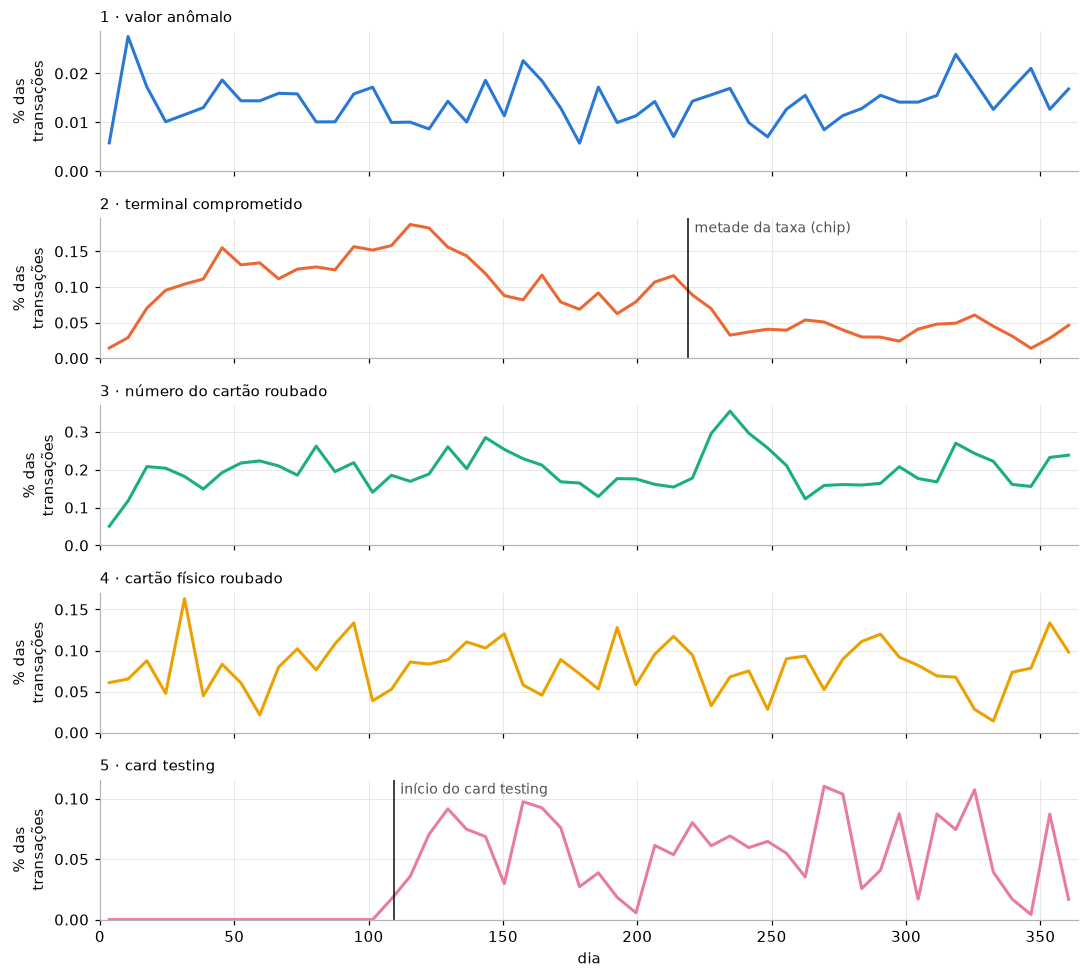

In [3]:
week = transactions.TX_TIME_DAYS // 7
full_weeks = week < NB_DAYS // 7  # the last, partial week is left out
per_week = transactions[full_weeks].groupby(week[full_weeks])
total = per_week.size()
changes = {2: 0.6 * NB_DAYS, 5: 0.3 * NB_DAYS}

fig, axes = plt.subplots(5, 1, figsize=(10, 9), sharex=True)
for ax, scenario in zip(axes, SCENARIO_NAMES):
    rate = 100 * per_week.TX_FRAUD_SCENARIO.apply(lambda s: (s == scenario).sum()) / total
    ax.plot(rate.index * 7 + 3.5, rate, color=SCENARIO_COLORS[scenario], lw=2)
    if scenario in changes:
        ax.axvline(changes[scenario], color=INK, lw=1)
        ax.annotate(
            "metade da taxa (chip)" if scenario == 2 else "início do card testing",
            (changes[scenario], 1), xycoords=("data", "axes fraction"),
            xytext=(4, -2), textcoords="offset points", va="top", fontsize=9, color=SECONDARY,
        )
    ax.set_ylim(bottom=0)
    ax.set_title(SCENARIO_NAMES[scenario], loc="left", fontsize=10)
    ax.set_ylabel("% das\ntransações")
axes[-1].set_xlabel("dia")
axes[-1].set_xlim(0, NB_DAYS - 1)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_taxa_por_cenario.pdf", bbox_inches="tight")
plt.show()

## Uma campanha: *card testing* → número do cartão roubado

Uma campanha em que o fraudador testa o cartão (cenário 5) e depois o usa em compras
CNP (cenário 3), com o mesmo `GT_CAMPAIGN_ID`. Em cinza, as compras legítimas da
vítima no mesmo período, que continuam normalmente.

In [4]:
by_campaign = frauds.groupby("GT_CAMPAIGN_ID")
scenarios_in = by_campaign.TX_FRAUD_SCENARIO.agg(set)
escalated = scenarios_in[scenarios_in.apply(lambda s: s == {3, 5})].index
bursts = frauds[frauds.GT_CAMPAIGN_ID.isin(escalated) & (frauds.TX_FRAUD_SCENARIO == 3)]
# A campaign with several bursts, in the middle of the period
n_days_used = bursts.groupby("GT_CAMPAIGN_ID").TX_TIME_DAYS.nunique()
start = by_campaign.TX_TIME_SECONDS.min()
candidates = n_days_used[(n_days_used >= 3)].index
candidates = [c for c in candidates if 0.4 * NB_DAYS < start[c] / 86400 < 0.8 * NB_DAYS]
campaign_id = candidates[0]
campaign = frauds[frauds.GT_CAMPAIGN_ID == campaign_id]
victim = campaign.CUSTOMER_ID.iloc[0]
t_first = campaign.TX_TIME_SECONDS.min()
t_last = campaign.TX_TIME_SECONDS.max()
own = transactions[(transactions.CUSTOMER_ID == victim) & (transactions.TX_FRAUD == 0)]
own = own[own.TX_TIME_SECONDS.between(t_first - 3 * 86400, t_last + 3 * 86400)]
campaign[["TX_DATETIME", "TX_FRAUD_SCENARIO", "TX_AMOUNT", "TX_TYPE", "GT_FRAUDSTER_ID"]]

,TX_DATETIME,TX_FRAUD_SCENARIO,TX_AMOUNT,TX_TYPE,GT_FRAUDSTER_ID
1456999,2023-05-27 16:19:49,5,3.70,CNP,296
1457000,2023-05-27 16:19:54,5,2.65,CNP,296
1457002,2023-05-27 16:20:00,5,2.31,CNP,296
1457003,2023-05-27 16:20:06,5,1.08,CNP,296
1457004,2023-05-27 16:20:09,5,3.95,CNP,296
1457028,2023-05-27 16:23:01,5,2.48,CNP,296
1471109,2023-05-29 05:03:32,3,76.00,CNP,296
1471252,2023-05-29 05:31:12,3,82.88,CNP,296
1471326,2023-05-29 05:46:54,3,178.84,CNP,296
1471431,2023-05-29 06:04:37,3,96.50,CNP,296


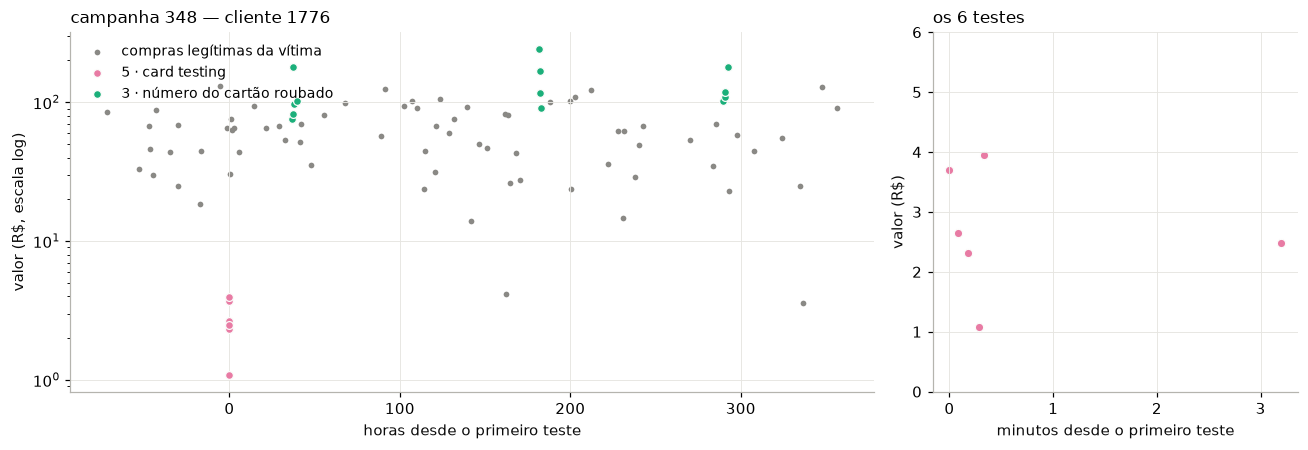

In [5]:
fig, (ax_all, ax_tests) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})

hours = lambda s: (s - t_first) / 3600  # noqa: E731
ax_all.scatter(hours(own.TX_TIME_SECONDS), own.TX_AMOUNT, s=14, color=MUTED, lw=0,
               label="compras legítimas da vítima")
for scenario in (5, 3):
    part = campaign[campaign.TX_FRAUD_SCENARIO == scenario]
    ax_all.scatter(hours(part.TX_TIME_SECONDS), part.TX_AMOUNT, s=26, color=SCENARIO_COLORS[scenario],
                   edgecolor="#fcfcfb", lw=0.8, label=SCENARIO_NAMES[scenario], zorder=3)
ax_all.set_yscale("log")
ax_all.set_xlabel("horas desde o primeiro teste")
ax_all.set_ylabel("valor (R$, escala log)")
ax_all.set_title(f"campanha {campaign_id} — cliente {victim}", loc="left", fontsize=11)
ax_all.legend(loc="upper left", frameon=False, fontsize=9)

tests = campaign[campaign.TX_FRAUD_SCENARIO == 5]
minutes = (tests.TX_TIME_SECONDS - t_first) / 60
ax_tests.scatter(minutes, tests.TX_AMOUNT, s=30, color=SCENARIO_COLORS[5], edgecolor="#fcfcfb", lw=0.8)
ax_tests.set_ylim(0, 6)
ax_tests.set_xlabel("minutos desde o primeiro teste")
ax_tests.set_ylabel("valor (R$)")
ax_tests.set_title(f"os {len(tests)} testes", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_campanha_card_testing.pdf", bbox_inches="tight")
plt.show()

## Valor por cenário

Distribuição dos valores das transações legítimas e das fraudes de cada cenário
(escala log). As fraudes do cenário 2 são compras legítimas rotuladas, então têm o
valor típico de um cliente; as dos cenários 1, 3 e 4 ficam acima do padrão do
cliente; as do cenário 5 são de R\$ 1 a 5.

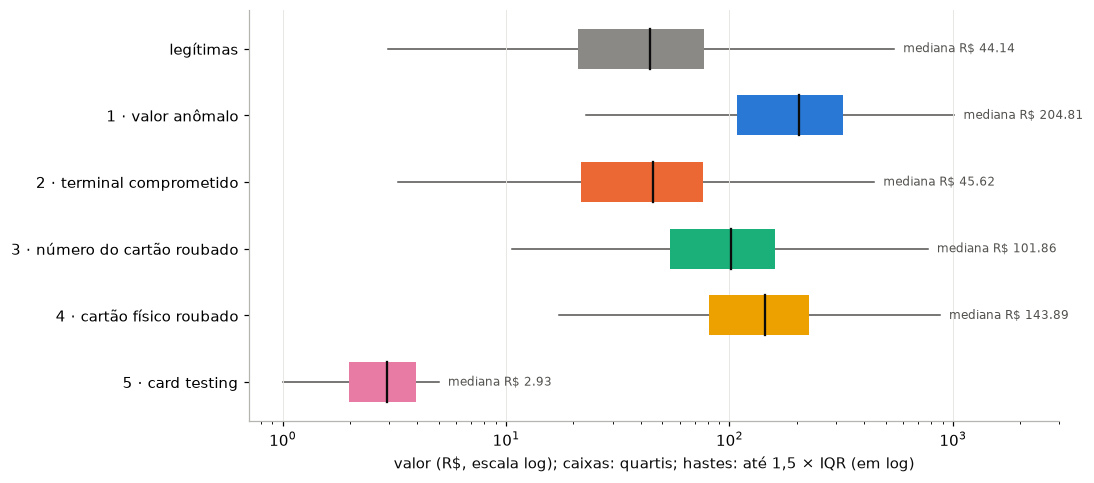

In [6]:
groups = [("legítimas", transactions.loc[transactions.TX_FRAUD == 0, "TX_AMOUNT"], MUTED)]
groups += [(SCENARIO_NAMES[s], frauds.loc[frauds.TX_FRAUD_SCENARIO == s, "TX_AMOUNT"], SCENARIO_COLORS[s])
           for s in SCENARIO_NAMES]
groups = groups[::-1]  # legitimate on top

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, (_, values, color) in enumerate(groups):
    # Box plot on the log scale: quartiles and whiskers computed on log10(amount)
    logs = np.log10(values[values > 0])
    q1, median, q3 = np.quantile(logs, [0.25, 0.5, 0.75])
    low = logs[logs >= q1 - 1.5 * (q3 - q1)].min()
    high = logs[logs <= q3 + 1.5 * (q3 - q1)].max()
    ax.plot([10**low, 10**high], [i, i], color=SECONDARY, lw=1, zorder=1)
    ax.barh(i, 10**q3 - 10**q1, left=10**q1, height=0.6, color=color, zorder=2)
    ax.plot([10**median] * 2, [i - 0.3, i + 0.3], color=INK, lw=1.5, zorder=3)
    ax.annotate(f"mediana R$ {10**median:,.2f}", (10**high, i), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=SECONDARY)
ax.set_yticks(range(len(groups)), [g[0] for g in groups])
ax.set_xscale("log")
ax.set_xlim(right=3e3)
ax.set_xlabel("valor (R$, escala log); caixas: quartis; hastes: até 1,5 × IQR (em log)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_valor_por_cenario.pdf", bbox_inches="tight")
plt.show()

## Cenário 1 e *drift*: o cenário 1 não rotula mais transações legítimas

Na v0.1, o cenário 1 rotulava como fraude toda transação legítima acima de R\$ 220.
Com *drift*, isso atinge principalmente os clientes cujo regime B gasta mais. Aqui,
comparamos, nos mesmos dados:

- a fração das transações legítimas que vêm do regime B;
- a regra antiga (limiar fixo de R\$ 220) aplicada a essas transações legítimas: de
  que regime vêm as transações que ela rotularia;
- o cenário 1 injetado: em que regime estava a vítima no dia da fraude
  (peso $w$ do regime B, pelo gabarito do cliente).

In [7]:
def victim_weight(row):
    # Weight of regime B for the victim of a fraud, on the day of the fraud
    profile = customers.loc[row.CUSTOMER_ID]
    def value(name):
        return 0 if pd.isna(profile[name]) else int(profile[name])
    drift = CustomerDrift(kind=profile.GT_DRIFT_TYPE, t0=value("GT_DRIFT_T0"),
                          transition_days=value("GT_DRIFT_L"), period_days=value("GT_DRIFT_PERIOD"),
                          active_days=value("GT_DRIFT_ACTIVE_DAYS"))
    return regime_weight(drift, np.array([row.TX_TIME_DAYS + 0.5]))[0]


legit = transactions[transactions.TX_FRAUD_SCENARIO.isin([0, 2])]  # scenario 2 labels legitimate purchases
s1 = frauds[frauds.TX_FRAUD_SCENARIO == 1]
over_threshold = legit[legit.TX_AMOUNT > 220]
check = pd.Series({
    "transações do cenário 1": len(s1),
    "das quais são transações legítimas (têm GT_REGIME)": int(s1.GT_REGIME.notna().sum()),
    "transações legítimas rotuladas por cenário diferente do 2": int(
        (legit.TX_FRAUD_SCENARIO != 0).sum() - (legit.TX_FRAUD_SCENARIO == 2).sum()
    ),
})
shares = pd.Series({
    "transações legítimas no regime B": (legit.GT_REGIME == "B").mean(),
    "limiar fixo de R$ 220 (v0.1): rotuladas do regime B": (over_threshold.GT_REGIME == "B").mean(),
    "cenário 1 injetado (v2): vítimas no regime B": s1.apply(victim_weight, axis=1).mean(),
})
display(check.to_frame("contagem"))
(100 * shares).round(1).to_frame("%")

,contagem
transações do cenário 1,513
das quais são transações legítimas (têm GT_REGIME),0
transações legítimas rotuladas por cenário diferente do 2,0


,%
transações legítimas no regime B,13.5
limiar fixo de R$ 220 (v0.1): rotuladas do regime B,85.9
cenário 1 injetado (v2): vítimas no regime B,13.5


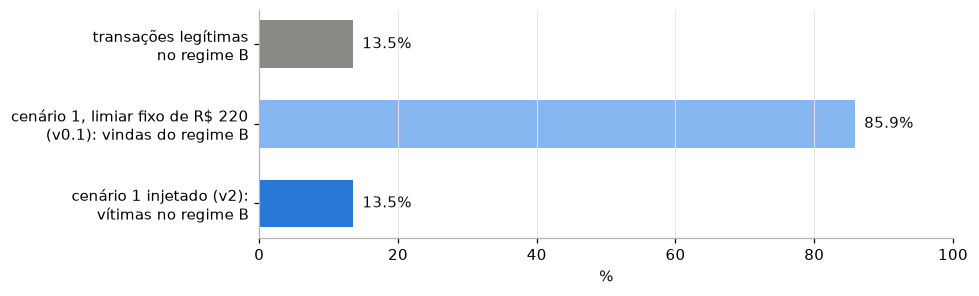

In [8]:
fig, ax = plt.subplots(figsize=(9, 2.8))
labels = ["transações legítimas\nno regime B", "cenário 1, limiar fixo de R$ 220\n(v0.1): vindas do regime B",
          "cenário 1 injetado (v2):\nvítimas no regime B"]
# Scenario 1 in its color; the old rule in a lighter step of the same hue
colors = [MUTED, "#86b6ef", SCENARIO_COLORS[1]]
y = np.arange(len(shares))[::-1]
ax.barh(y, 100 * shares.to_numpy(), color=colors, height=0.6)
for yi, value in zip(y, 100 * shares.to_numpy()):
    ax.annotate(f"{value:.1f}%", (value, yi), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=10, color=INK)
ax.set_yticks(y, labels)
ax.set_xlim(0, 100)
ax.set_xlabel("%")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "fraudes_cenario1_regime_b.pdf", bbox_inches="tight")
plt.show()